# Isolation Forest: A Complete, Project-Based Tutorial for Bioinformatics
## Detecting Anomalous Samples in Gene Expression Data

This notebook teaches **Isolation Forest** from the ground up. We will first build an intuition for anomaly detection, then apply the algorithm to a simple two-dimensional dataset, and finally explore a synthetic gene-expression dataset.

### Learning objectives
- Understand anomaly detection and unsupervised learning.
- Explain the intuition behind Isolation Forest and isolation trees.
- Interpret path length and the outputs of scikit-learn's implementation.
- Train a model and evaluate it when synthetic ground-truth labels are available.
- Visualize potential anomalies using scatter plots, a heatmap, and PCA.
- Investigate genes with unusually high deviations in a flagged sample.
- Recognize the scientific limitations of anomaly detection in bioinformatics.

> **Important scientific note:** All datasets in this notebook are synthetic and are created for teaching. An anomalous sample is not automatically a faulty experiment, a disease indicator, or a biologically meaningful discovery.

## 0. Environment Setup

This notebook requires Python and the following packages:
- `numpy` for numerical operations
- `pandas` for tabular data
- `matplotlib` for plots
- `scikit-learn` for Isolation Forest, scaling, PCA, and evaluation metrics

If you need to install the packages, run the following cell. If your environment has no internet access, install the packages in advance using an appropriate offline package source.

In [1]:
# Uncomment this line if the required packages are not installed.
# %pip install numpy pandas matplotlib scikit-learn

## 1. Import Libraries and Set a Random Seed

A fixed random seed makes the synthetic data and model results reproducible. Exact results can still vary across library versions or computational environments.

In [2]:
# Import numerical computing tools.
import numpy as np

# Import tools for tabular data.
import pandas as pd

# Import plotting tools.
import matplotlib.pyplot as plt

# Import the Isolation Forest estimator.
from sklearn.ensemble import IsolationForest

# Import a helper for generating clustered synthetic data.
from sklearn.datasets import make_blobs

# Import preprocessing and dimensionality-reduction tools.
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Import evaluation metrics.
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)

# Set a seed for reproducible examples.
RANDOM_STATE = 42
rng = np.random.RandomState(RANDOM_STATE)

# Report the installed scikit-learn version.
import sklearn
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.0


## 2. What Is Anomaly Detection?

**Anomaly detection** is the process of identifying observations that differ from the dominant patterns in a dataset.

### Classification vs. unsupervised anomaly detection

- **Classification:** A model learns from labeled examples, such as samples labeled `healthy` or `disease`.
- **Unsupervised anomaly detection:** A model does not need anomaly labels during fitting. It searches for observations that appear unusual relative to the data's structure.

In bioinformatics, an unusual expression profile could reflect:
- A real biological difference.
- A batch effect or another technical artifact.
- Contamination or a different mixture of cell types.
- A measurement or sample-preparation error.

The algorithm identifies unusual patterns; it does **not** determine the cause by itself.

## 3. The Core Idea Behind Isolation Forest

Isolation Forest is an anomaly-detection algorithm based on a simple intuition:

> Observations that are unusual are often easier to isolate from the rest of the data.

The algorithm builds many randomized **isolation trees**. At each internal node, it randomly chooses a feature and a split value, then divides the observations into two groups. This process continues until a stopping condition is reached.

- An observation isolated after relatively few splits has a short path and is often more anomalous.
- An observation that requires more splits to isolate is often more typical of the dataset.

This is a statistical tendency, not a rule that holds for every observation.

### Why is it called Isolation Forest?

- **Isolation:** The trees aim to separate observations from one another.
- **Forest:** The algorithm combines many trees rather than relying on a single tree.

Unlike a conventional Random Forest used for classification or regression, Isolation Forest uses randomized splits to isolate observations.

## 4. Path Length and the Mathematical Intuition

Let $h(x)$ be the path length of observation $x$ in one isolation tree. The path length is the number of splits required to reach the leaf containing that observation.

Because each tree is randomized, a sample can have different path lengths in different trees. We therefore consider the average path length across $T$ trees:

$$
E[h(x)] = \frac{1}{T}\sum_{t=1}^{T} h_t(x)
$$

The original Isolation Forest paper defines a normalized anomaly score using the expected path length:

$$
s(x,n) = 2^{-\frac{E[h(x)]}{c(n)}}
$$

where:

- $n$ is the sample size used to build a tree.
- $E[h(x)]$ is the average path length for observation $x$.
- $c(n)$ is a normalization term based on the expected path length of an unsuccessful search in a binary search tree.

A commonly used expression for the normalization term is:

$$
c(n)=2H(n-1)-\frac{2(n-1)}{n}
$$

where $H(i)$ is the $i$-th harmonic number:

$$
H(i)=\sum_{k=1}^{i}\frac{1}{k}
$$

For large $i$, the harmonic number can be approximated by:

$$
H(i)\approx \ln(i)+\gamma
$$

where $\gamma$ is the Euler–Mascheroni constant.

### Important implementation detail

The theoretical score above is defined so that a **larger** score indicates a more anomalous observation. In scikit-learn, the score direction is reversed:

- `score_samples(X)`: lower (more negative) values generally indicate more anomalous observations.
- `decision_function(X)`: negative values are generally flagged as outliers.
- `predict(X)`: returns `1` for an inlier and `-1` for an outlier.

Always check the documentation for the specific implementation you are using.

## 5. A Tiny Example with Two Features

Imagine two gene-like features, `gene_A` and `gene_B`. Most samples have similar values, while the final sample differs substantially in both features.

This small table is only an illustration; a real anomaly-detection model needs to consider the full feature space and many randomized trees.

In [3]:
# Create a small example in which the last sample has much larger values.
toy_data = pd.DataFrame(
    {
        "gene_A": [4.8, 5.1, 4.9, 5.3, 5.0, 18.5],
        "gene_B": [7.2, 7.0, 7.4, 7.1, 7.3, 21.0],
    },
    index=[f"Sample_{i:02d}" for i in range(1, 7)],
)

# Display the toy dataset.
display(toy_data)

,gene_A,gene_B
Sample_01,4.8,7.2
Sample_02,5.1,7.0
Sample_03,4.9,7.4
Sample_04,5.3,7.1
Sample_05,5.0,7.3
Sample_06,18.5,21.0


## 6. Create a Synthetic Two-Dimensional Dataset

We will generate a dense cluster of ordinary observations and add several points far from the cluster.

The ground-truth labels are retained **only for evaluation after fitting**. They are not supplied to the model during training.

In [4]:
# Generate a dense group of ordinary observations.
X_normal, _ = make_blobs(
    n_samples=300,
    centers=1,
    n_features=2,
    cluster_std=0.8,
    random_state=RANDOM_STATE,
)

# Generate points spread across a wider range to act as artificial anomalies.
rng_2d = np.random.RandomState(RANDOM_STATE)
X_outliers = rng_2d.uniform(low=-8, high=8, size=(15, 2))

# Combine ordinary observations and artificial anomalies.
X = np.vstack([X_normal, X_outliers])

# Ground-truth labels: 1 = ordinary, -1 = artificial anomaly.
y_true = np.concatenate([
    np.ones(len(X_normal), dtype=int),
    -np.ones(len(X_outliers), dtype=int),
])

print("Dataset shape:", X.shape)
print("Ordinary samples:", np.sum(y_true == 1))
print("Artificial anomalies:", np.sum(y_true == -1))

Dataset shape: (315, 2)
Ordinary samples: 300
Artificial anomalies: 15


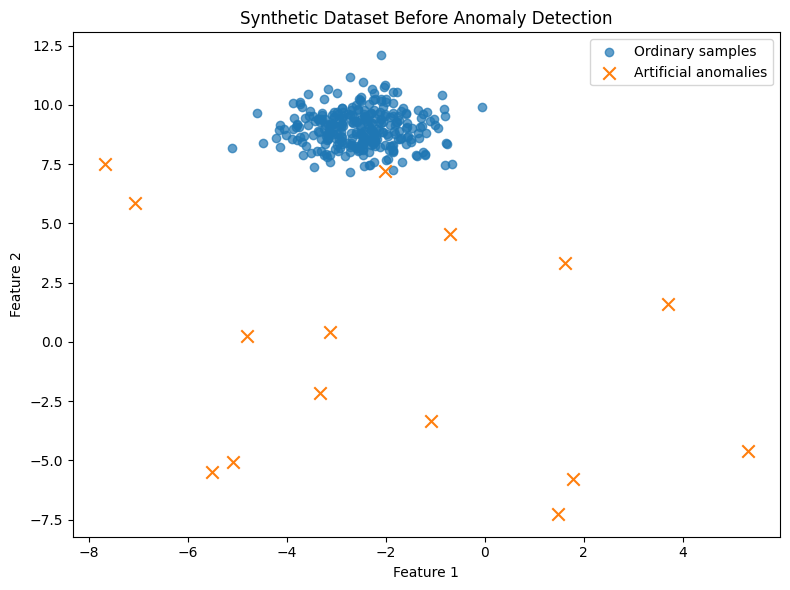

In [5]:
# Plot the dataset before applying the anomaly-detection model.
plt.figure(figsize=(8, 6))

# Display the ordinary observations.
plt.scatter(
    X[y_true == 1, 0],
    X[y_true == 1, 1],
    label="Ordinary samples",
    alpha=0.7,
)

# Display the artificial anomalies with a different marker.
plt.scatter(
    X[y_true == -1, 0],
    X[y_true == -1, 1],
    label="Artificial anomalies",
    marker="x",
    s=80,
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Dataset Before Anomaly Detection")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Train an Isolation Forest Model

The main parameters used here are:

| Parameter | Meaning |
|---|---|
| `n_estimators` | Number of isolation trees |
| `max_samples` | Number of observations sampled for each tree |
| `contamination` | Assumed outlier fraction used to set the decision threshold |
| `max_features` | Number or fraction of features considered by each tree |
| `random_state` | Seed for reproducible random choices |
| `n_jobs` | Number of parallel jobs; `-1` uses available CPU cores |

Setting `contamination=0.05` does **not** establish that exactly 5% of the observations are truly anomalous. It helps determine the model's decision threshold.

In [6]:
# Initialize the Isolation Forest model.
model = IsolationForest(
    n_estimators=200,
    max_samples="auto",
    contamination=0.05,
    max_features=1.0,
    bootstrap=False,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# Fit the model using features only; do not pass y_true.
model.fit(X)

# Predict inliers (1) and outliers (-1).
y_pred = model.predict(X)

# Calculate decision scores relative to the model's threshold.
decision_scores = model.decision_function(X)

# Obtain raw sample scores; lower values generally mean more anomalous.
sample_scores = model.score_samples(X)

print("Predicted ordinary:", np.sum(y_pred == 1))
print("Predicted anomalies:", np.sum(y_pred == -1))

Predicted ordinary: 299
Predicted anomalies: 16


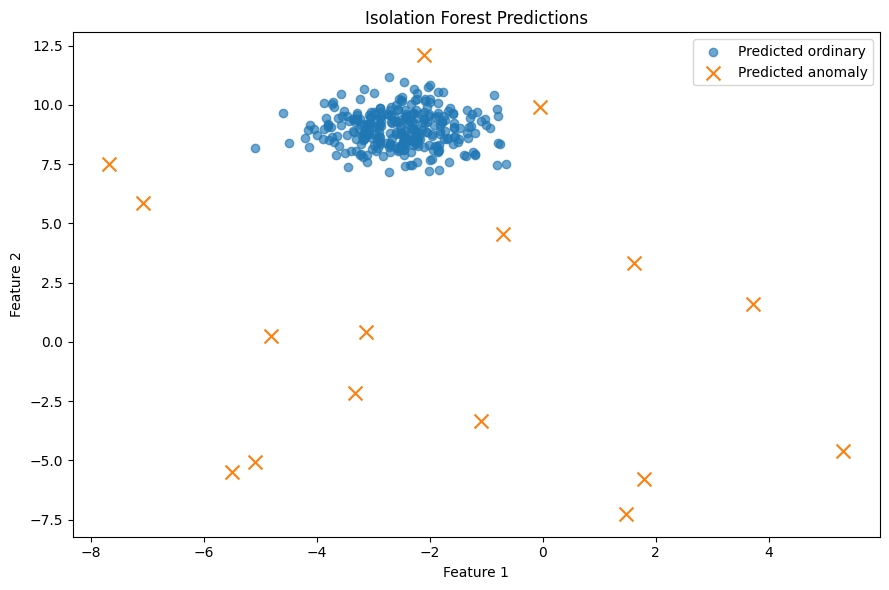

In [7]:
# Create a mask identifying observations flagged as anomalies.
anomaly_mask = y_pred == -1

# Compare the two predicted groups visually.
plt.figure(figsize=(9, 6))
plt.scatter(
    X[~anomaly_mask, 0],
    X[~anomaly_mask, 1],
    label="Predicted ordinary",
    alpha=0.65,
)
plt.scatter(
    X[anomaly_mask, 0],
    X[anomaly_mask, 1],
    label="Predicted anomaly",
    marker="x",
    s=100,
)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Isolation Forest Predictions")
plt.legend()
plt.tight_layout()
plt.show()

### 8.1. Visualize the Anomaly-Score Landscape

A scatter plot shows individual observations, but a score map also shows how the model evaluates locations between observations. We evaluate the fitted model on a dense grid and color each location by its `decision_function` value.

- Negative decision-function values are on the outlier side of the model's threshold.
- Positive values are on the inlier side.
- The zero contour marks the decision threshold in this two-dimensional example.

This is a visualization of the model's score surface, not a guarantee that every point in a colored region has the same biological meaning.

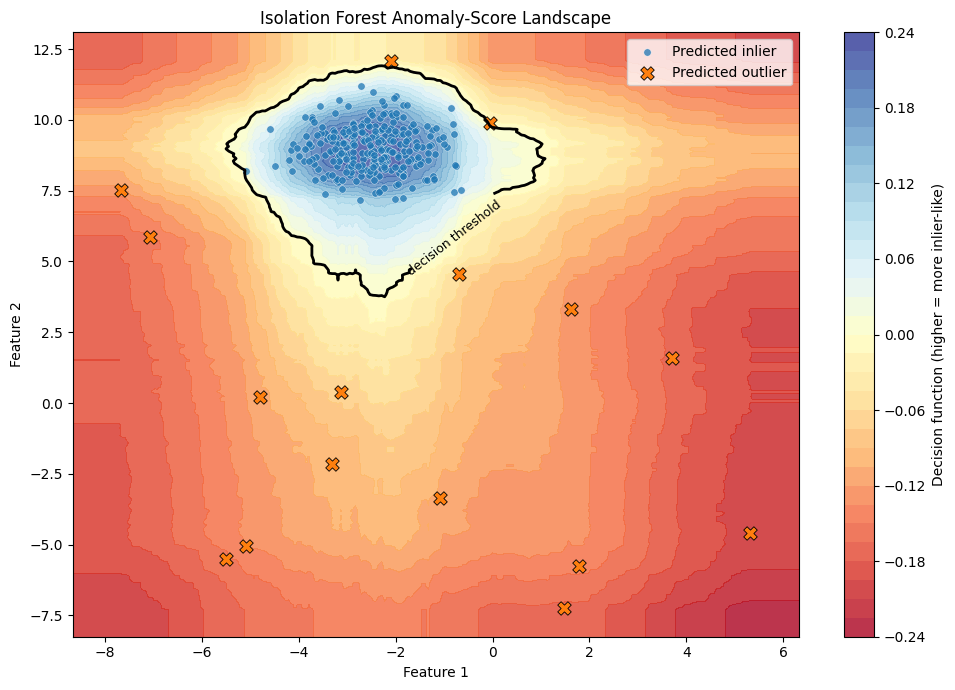

In [8]:
# Build a grid covering the observed two-dimensional feature space.
x_min, x_max = X[:, 0].min() - 1.0, X[:, 0].max() + 1.0
y_min, y_max = X[:, 1].min() - 1.0, X[:, 1].max() + 1.0
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250),
)
grid = np.c_[xx.ravel(), yy.ravel()]

# Evaluate the model's decision function at every grid location.
grid_scores = model.decision_function(grid).reshape(xx.shape)

# Plot the score surface and the zero-score decision contour.
fig, ax = plt.subplots(figsize=(10, 7))
surface = ax.contourf(
    xx, yy, grid_scores,
    levels=30,
    cmap="RdYlBu",
    alpha=0.82,
)
contour = ax.contour(
    xx, yy, grid_scores,
    levels=[0],
    colors="black",
    linewidths=2,
)
ax.clabel(contour, fmt={0: "decision threshold"}, inline=True, fontsize=9)

# Overlay the observed samples using the model's predicted labels.
ax.scatter(
    X[y_pred == 1, 0], X[y_pred == 1, 1],
    s=28, alpha=0.75, label="Predicted inlier",
    edgecolor="white", linewidth=0.35,
)
ax.scatter(
    X[y_pred == -1, 0], X[y_pred == -1, 1],
    s=95, marker="X", label="Predicted outlier",
    edgecolor="black", linewidth=0.6,
)
fig.colorbar(surface, ax=ax, label="Decision function (higher = more inlier-like)")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_title("Isolation Forest Anomaly-Score Landscape")
ax.legend(loc="best")
fig.tight_layout()
plt.show()

## 8. Understand and Rank the Model Outputs

The table below includes the input features, predicted labels, and both score types.

Sorting `score_samples` in ascending order puts the observations with the lowest raw scores first. This can help prioritize observations for manual review, but it does not explain why a sample is unusual.

In [9]:
# Build a table containing the input features and model outputs.
results = pd.DataFrame({
    "feature_1": X[:, 0],
    "feature_2": X[:, 1],
    "prediction": y_pred,
    "decision_function": decision_scores,
    "score_samples": sample_scores,
})

# Add readable labels for the predicted classes.
results["predicted_label"] = np.where(
    results["prediction"] == -1,
    "Anomaly",
    "Normal",
)

# Rank the most anomalous observations first.
results_sorted = results.sort_values(
    "score_samples",
    ascending=True,
)

display(results_sorted.head(10))

,feature_1,feature_2,prediction,decision_function,score_samples,predicted_label
306,5.319082,-4.602574,-1,-0.203297,-0.785416,Anomaly
314,1.478633,-7.256793,-1,-0.171797,-0.753916,Anomaly
301,3.711903,1.578536,-1,-0.169676,-0.751795,Anomaly
302,-5.503702,-5.504088,-1,-0.153904,-0.736023,Anomaly
303,-7.070662,5.858818,-1,-0.151696,-0.733815,Anomaly
310,1.789646,-5.768098,-1,-0.142784,-0.724903,Anomaly
307,-5.090801,-5.065528,-1,-0.134444,-0.716563,Anomaly
304,1.617840,3.329161,-1,-0.129138,-0.711257,Anomaly
305,-7.670648,7.518558,-1,-0.122950,-0.705069,Anomaly
313,-4.805219,0.227751,-1,-0.110890,-0.693009,Anomaly


## 9. Evaluate the Model Using Synthetic Ground Truth

In real projects, reliable labels for all anomalies are often unavailable. In this controlled example, however, we know which observations we artificially generated as anomalies.

We can therefore calculate:

- **Precision:** Of the observations flagged as anomalous, what fraction are artificial anomalies?
- **Recall:** Of all artificial anomalies, what fraction did the model detect?
- **F1-score:** The harmonic mean of precision and recall.
- **Confusion matrix:** Counts of correct and incorrect predictions.

These metrics evaluate performance on this synthetic dataset only. They do not guarantee similar performance on real biological data.

In [10]:
# Convert labels to binary form: 1 = anomaly, 0 = ordinary.
y_true_binary = (y_true == -1).astype(int)
y_pred_binary = (y_pred == -1).astype(int)

# Calculate evaluation metrics.
precision = precision_score(
    y_true_binary, y_pred_binary, zero_division=0
)
recall = recall_score(
    y_true_binary, y_pred_binary, zero_division=0
)
f1 = f1_score(
    y_true_binary, y_pred_binary, zero_division=0
)

print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")

print("\\nClassification report:")
print(classification_report(
    y_true_binary,
    y_pred_binary,
    target_names=["Ordinary", "Artificial anomaly"],
    zero_division=0,
))

print("Confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(y_true_binary, y_pred_binary))

Precision: 0.875
Recall:    0.933
F1-score:  0.903
\nClassification report:
                    precision    recall  f1-score   support

          Ordinary       1.00      0.99      0.99       300
Artificial anomaly       0.88      0.93      0.90        15

          accuracy                           0.99       315
         macro avg       0.94      0.96      0.95       315
      weighted avg       0.99      0.99      0.99       315

Confusion matrix (rows=true, columns=predicted):
[[298   2]
 [  1  14]]


### 9.1. Visualize the Confusion Matrix

The confusion matrix separates four outcomes: true positives, false positives, true negatives, and false negatives. Here, an anomaly is the positive class. Because the dataset is synthetic, we know which observations were generated as anomalies and can compare predictions against that ground truth.

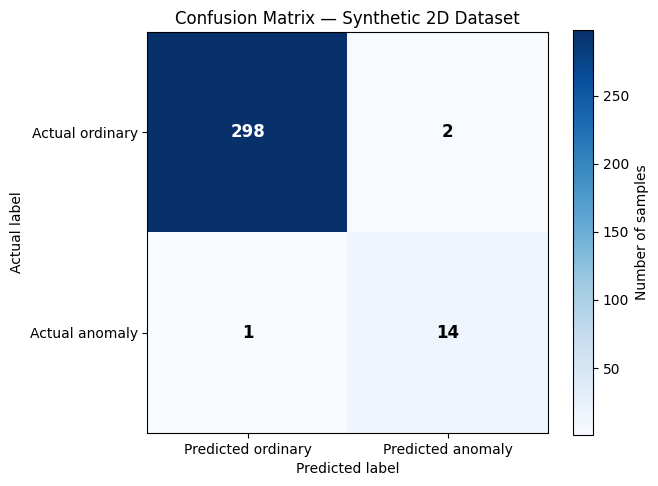

In [11]:
# Compute the confusion matrix with a fixed class order: ordinary, anomaly.
cm = confusion_matrix(y_true_binary, y_pred_binary, labels=[0, 1])

# Draw a readable heatmap using Matplotlib.
fig, ax = plt.subplots(figsize=(6.5, 5))
image = ax.imshow(cm, cmap="Blues")
fig.colorbar(image, ax=ax, label="Number of samples")
ax.set_xticks([0, 1], labels=["Predicted ordinary", "Predicted anomaly"])
ax.set_yticks([0, 1], labels=["Actual ordinary", "Actual anomaly"])
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_title("Confusion Matrix — Synthetic 2D Dataset")

# Write each cell count on top of the heatmap.
threshold = cm.max() / 2 if cm.size else 0
for row in range(cm.shape[0]):
    for col in range(cm.shape[1]):
        ax.text(
            col, row, f"{cm[row, col]:,}",
            ha="center", va="center",
            color="white" if cm[row, col] > threshold else "black",
            fontsize=12, fontweight="bold",
        )

fig.tight_layout()
plt.show()

## 10. Experiment with Model Parameters

### 10.1. Change the Number of Trees

More trees can make results more stable, at the cost of additional computation. The number of detected anomalies alone is not a quality metric, especially when `contamination` is held constant.

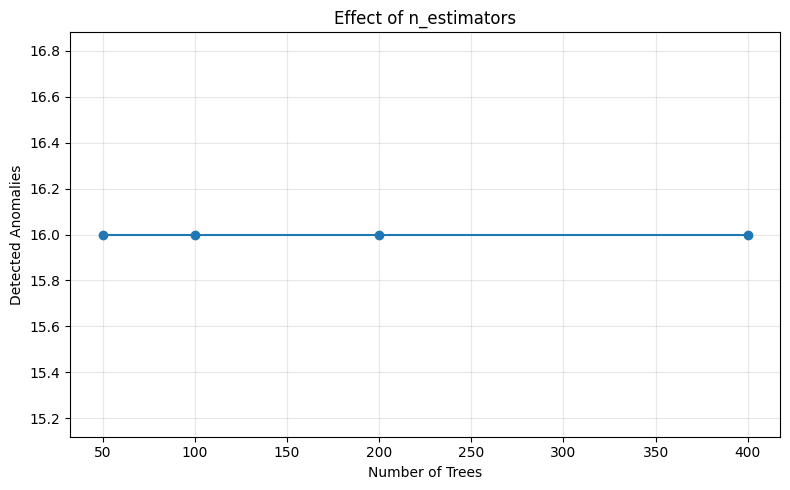

In [12]:
# Define the number of trees to compare.
tree_counts = [50, 100, 200, 400]
detected_counts = []

# Fit a separate model for each tree count.
for tree_count in tree_counts:
    experiment_model = IsolationForest(
        n_estimators=tree_count,
        contamination=0.05,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    experiment_model.fit(X)
    experiment_predictions = experiment_model.predict(X)
    detected_counts.append(np.sum(experiment_predictions == -1))

# Plot the number of detected observations.
plt.figure(figsize=(8, 5))
plt.plot(tree_counts, detected_counts, marker="o")
plt.xlabel("Number of Trees")
plt.ylabel("Detected Anomalies")
plt.title("Effect of n_estimators")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 10.2. Change `contamination`

The contamination parameter influences the decision threshold. Increasing it will generally cause more observations to be flagged, but it should not be interpreted as the known true anomaly rate.

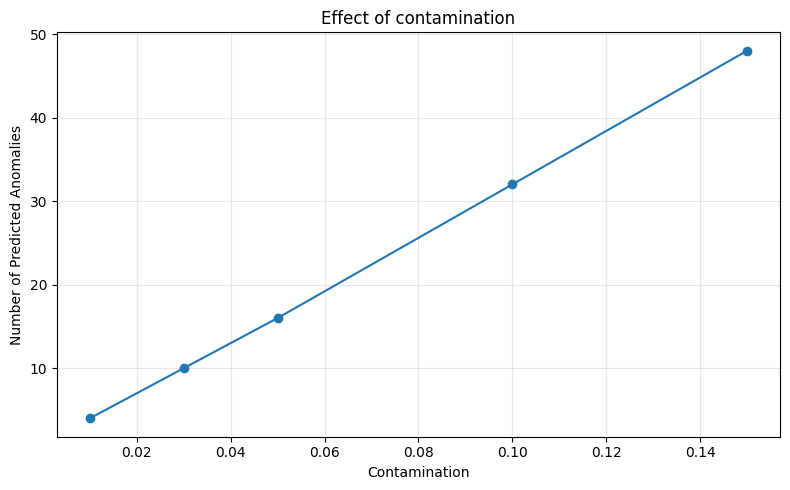

In [13]:
# Define contamination levels to compare.
contamination_values = [0.01, 0.03, 0.05, 0.10, 0.15]
anomaly_counts = []

# Fit and evaluate a model for each threshold setting.
for contamination_value in contamination_values:
    experiment_model = IsolationForest(
        n_estimators=200,
        contamination=contamination_value,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    experiment_model.fit(X)
    experiment_predictions = experiment_model.predict(X)
    anomaly_counts.append(np.sum(experiment_predictions == -1))

# Visualize the relationship between contamination and detections.
plt.figure(figsize=(8, 5))
plt.plot(contamination_values, anomaly_counts, marker="o")
plt.xlabel("Contamination")
plt.ylabel("Number of Predicted Anomalies")
plt.title("Effect of contamination")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Main Project: Anomaly Detection in Gene Expression Data

In transcriptomics, measurements are often organized as a matrix:
- Each row represents a biological sample.
- Each column represents a gene.
- Each cell contains a measured expression value.

The goal is to identify samples whose overall expression profiles differ from the dominant pattern.

Potential explanations for unusual profiles include biological differences, batch effects, contamination, differences in cell composition, or technical problems. Isolation Forest does not determine which explanation is correct.

For this tutorial, we will create a synthetic expression matrix. The values are not real measurements and do not correspond to any patient or disease.

In [14]:
# Create a random-number generator for the synthetic biological example.
rng_bio = np.random.RandomState(RANDOM_STATE)

# Define the number of samples and genes.
n_samples = 120
n_genes = 40

# Generate synthetic expression-like values.
# Rows are samples; columns are genes.
expression = rng_bio.normal(
    loc=5.0,
    scale=1.0,
    size=(n_samples, n_genes),
)

# Choose a small number of samples for artificial anomaly injection.
n_anomalies = 6
anomaly_indices = rng_bio.choice(
    n_samples,
    size=n_anomalies,
    replace=False,
)

# Choose genes that will be shifted in the selected samples.
altered_gene_indices = [2, 7, 11, 19, 27, 34]

# Inject positive shifts into the selected sample-gene combinations.
for sample_index in anomaly_indices:
    expression[sample_index, altered_gene_indices] += rng_bio.uniform(
        low=4.0,
        high=7.0,
        size=len(altered_gene_indices),
    )

# Create readable sample and gene identifiers.
sample_ids = [f"Sample_{i:03d}" for i in range(1, n_samples + 1)]
gene_names = [f"Gene_{i:02d}" for i in range(1, n_genes + 1)]

# Convert the NumPy matrix into a labeled DataFrame.
expression_df = pd.DataFrame(
    expression,
    index=sample_ids,
    columns=gene_names,
)

# Keep artificial ground truth for evaluation only.
# 1 = artificially modified sample, 0 = other sample.
biological_truth = np.zeros(n_samples, dtype=int)
biological_truth[anomaly_indices] = 1

print("Expression matrix shape:", expression_df.shape)
print("Artificially modified sample IDs:")
print(expression_df.index[anomaly_indices].tolist())

display(expression_df.iloc[:5, :8])

Expression matrix shape: (120, 40)
Artificially modified sample IDs:
['Sample_016', 'Sample_095', 'Sample_056', 'Sample_057', 'Sample_111', 'Sample_040']


,Gene_01,Gene_02,Gene_03,Gene_04,Gene_05,Gene_06,Gene_07,Gene_08
Sample_001,5.496714,4.861736,5.647689,6.523030,4.765847,4.765863,6.579213,5.767435
Sample_002,5.738467,5.171368,4.884352,4.698896,3.521478,4.280156,4.539361,6.057122
Sample_003,4.780328,5.357113,6.477894,4.481730,4.191506,4.498243,5.915402,5.328751
Sample_004,5.791032,4.090613,6.402794,3.598149,5.586857,7.190456,4.009464,4.433702
Sample_005,4.025318,5.787085,6.158596,4.179318,5.963376,5.412781,5.822060,6.896793


## 12. Inspect the Expression Matrix

Before fitting a model, check the matrix dimensions, missing values, infinite values, and basic descriptive statistics.

Do not automatically replace missing values with zero. In expression data, zero can be a meaningful measurement and is not equivalent to a missing value.

In [15]:
# Count missing values across the entire matrix.
missing_count = int(expression_df.isna().sum().sum())

# Count infinite values in the numerical matrix.
infinite_count = int(np.isinf(expression_df.to_numpy()).sum())

print("Missing values:", missing_count)
print("Infinite values:", infinite_count)

# Inspect summary statistics for the first ten genes.
display(expression_df.describe().T.head(10))

# Convert the DataFrame to a numerical feature matrix.
X_expression = expression_df.to_numpy(dtype=float)

# Stop early if the matrix contains invalid numerical values.
if not np.isfinite(X_expression).all():
    raise ValueError(
        "The expression matrix contains NaN or infinite values. "
        "Resolve them using a scientifically appropriate strategy."
    )

Missing values: 0
Infinite values: 0


,count,mean,std,min,25%,50%,75%,max
Gene_01,120.0,5.021057,1.011596,2.500594,4.319938,5.101445,5.630562,7.526932
Gene_02,120.0,5.119742,1.045202,2.396863,4.417842,5.125314,5.691646,7.985259
Gene_03,120.0,5.124059,1.466880,2.810078,4.201130,4.955120,5.680986,11.569511
Gene_04,120.0,5.007617,1.008083,2.703819,4.195435,5.122600,5.722183,7.092387
Gene_05,120.0,4.937856,0.943460,2.252495,4.232782,4.907400,5.648466,7.133033
Gene_06,120.0,4.911291,1.063997,1.829574,4.154931,4.922583,5.633480,7.439752
Gene_07,120.0,4.846506,0.955932,2.295608,4.280341,4.884273,5.425852,7.485190
Gene_08,120.0,5.354188,1.651987,2.145373,4.427756,5.113032,5.813476,13.263216
Gene_09,120.0,5.058543,0.948280,3.048898,4.467740,5.085178,5.725733,7.056544
Gene_10,120.0,5.124573,1.025777,2.683856,4.467943,5.020308,5.849230,8.852731


## 13. Visualize the Expression Matrix as a Heatmap

This heatmap displays the first 30 samples and first 20 genes. The color bar represents the synthetic expression-like values.

For a real dataset, the appropriate transformation, color scale, and sample ordering depend on the assay, normalization method, and scientific question.

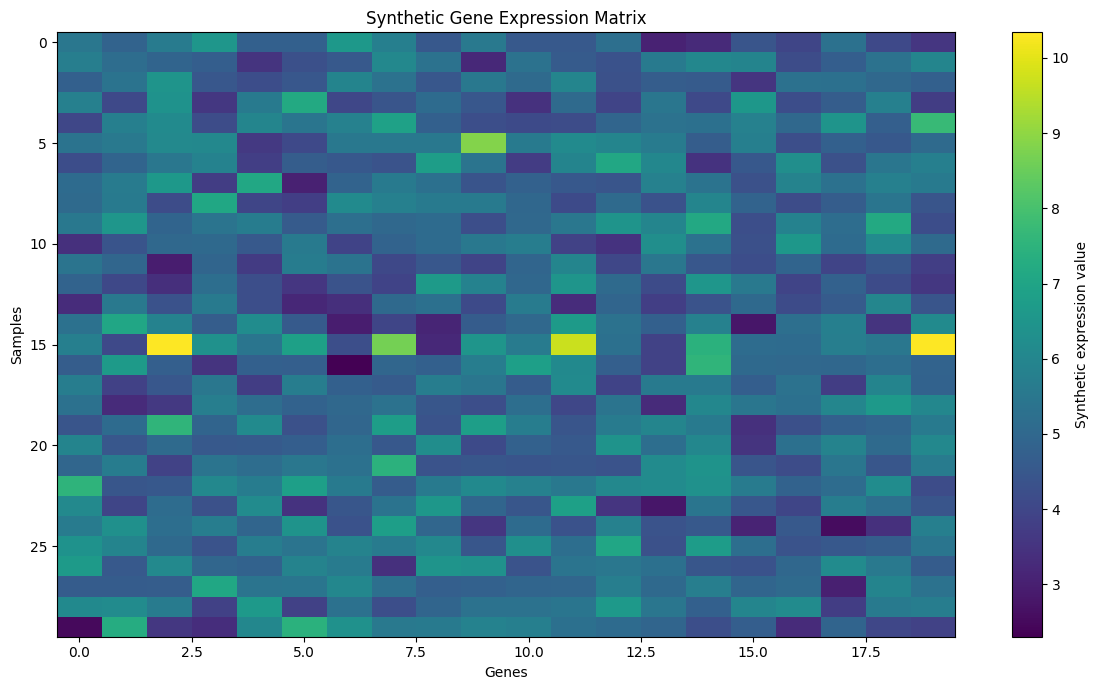

In [16]:
# Plot a subset of the expression matrix.
plt.figure(figsize=(12, 7))
plt.imshow(
    expression_df.iloc[:30, :20],
    aspect="auto",
    interpolation="nearest",
)
plt.colorbar(label="Synthetic expression value")
plt.xlabel("Genes")
plt.ylabel("Samples")
plt.title("Synthetic Gene Expression Matrix")
plt.tight_layout()
plt.show()

## 14. Preprocessing and Scaling

Isolation Forest is based on randomized tree splits and is generally less dependent on feature scaling than distance-based methods. Nevertheless, preprocessing is crucial for biological data, and transformations can affect the result.

For this demonstration, we will use `StandardScaler`, which transforms each feature approximately to mean zero and standard deviation one:

$$
z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}
$$

where:

- $x_{ij}$ is the value for sample $i$ and gene $j$.
- $\mu_j$ is the mean of gene $j$.
- $\sigma_j$ is the standard deviation of gene $j$.

This is an educational choice, not a universal prescription for expression data. Raw counts, normalized counts, and log-transformed expression values should not be treated as interchangeable.

For a train/test evaluation, fit preprocessing steps on the training data only, then apply the fitted transformations to held-out data. That helps avoid information leakage.

In [17]:
# Initialize the standardization transformer.
scaler = StandardScaler()

# Fit the scaler and transform the synthetic matrix.
X_expression_scaled = scaler.fit_transform(X_expression)

print("Scaled matrix shape:", X_expression_scaled.shape)
print(
    "Means of the first five genes:",
    np.round(X_expression_scaled.mean(axis=0)[:5], 3),
)

Scaled matrix shape: (120, 40)
Means of the first five genes: [ 0. -0.  0.  0. -0.]


## 15. Fit Isolation Forest to the Gene Expression Profiles

We will use `contamination="auto"` for this example. The model is trained without the artificial labels; those labels are only used later for evaluation.

In [18]:
# Initialize the Isolation Forest model for the expression profiles.
gene_model = IsolationForest(
    n_estimators=300,
    max_samples="auto",
    contamination="auto",
    max_features=1.0,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# Fit the model using expression features only.
gene_model.fit(X_expression_scaled)

# Predict inliers (1) and outliers (-1).
gene_predictions = gene_model.predict(X_expression_scaled)

# Calculate decision scores and raw sample scores.
gene_decision_scores = gene_model.decision_function(X_expression_scaled)
gene_sample_scores = gene_model.score_samples(X_expression_scaled)

# Build a results table indexed by sample identifier.
gene_results = pd.DataFrame({
    "sample_id": expression_df.index,
    "prediction": gene_predictions,
    "decision_function": gene_decision_scores,
    "score_samples": gene_sample_scores,
}, index=expression_df.index)

# Add readable categories.
gene_results["status"] = np.where(
    gene_results["prediction"] == -1,
    "Potential anomaly",
    "Not flagged",
)

print("Predicted anomalies:", int((gene_predictions == -1).sum()))

# Display the samples with the lowest raw scores first.
display(gene_results.sort_values("score_samples").head(12))

Predicted anomalies: 5


,sample_id,prediction,decision_function,score_samples,status
Sample_016,Sample_016,-1,-0.038749,-0.538749,Potential anomaly
Sample_057,Sample_057,-1,-0.036605,-0.536605,Potential anomaly
Sample_056,Sample_056,-1,-0.026575,-0.526575,Potential anomaly
Sample_095,Sample_095,-1,-0.013302,-0.513302,Potential anomaly
Sample_040,Sample_040,-1,-0.005224,-0.505224,Potential anomaly
Sample_111,Sample_111,1,0.000661,-0.499339,Not flagged
Sample_100,Sample_100,1,0.018542,-0.481458,Not flagged
Sample_051,Sample_051,1,0.021583,-0.478417,Not flagged
Sample_049,Sample_049,1,0.024636,-0.475364,Not flagged
Sample_073,Sample_073,1,0.026264,-0.473736,Not flagged


### 15.1. Inspect the Distribution of Gene-Expression Anomaly Scores

The raw `score_samples` values help rank samples from more anomalous to less anomalous. In scikit-learn, lower (more negative) values are generally more anomalous. The vertical line below shows the model's learned threshold (`offset_`); samples below it are flagged by the default decision rule.

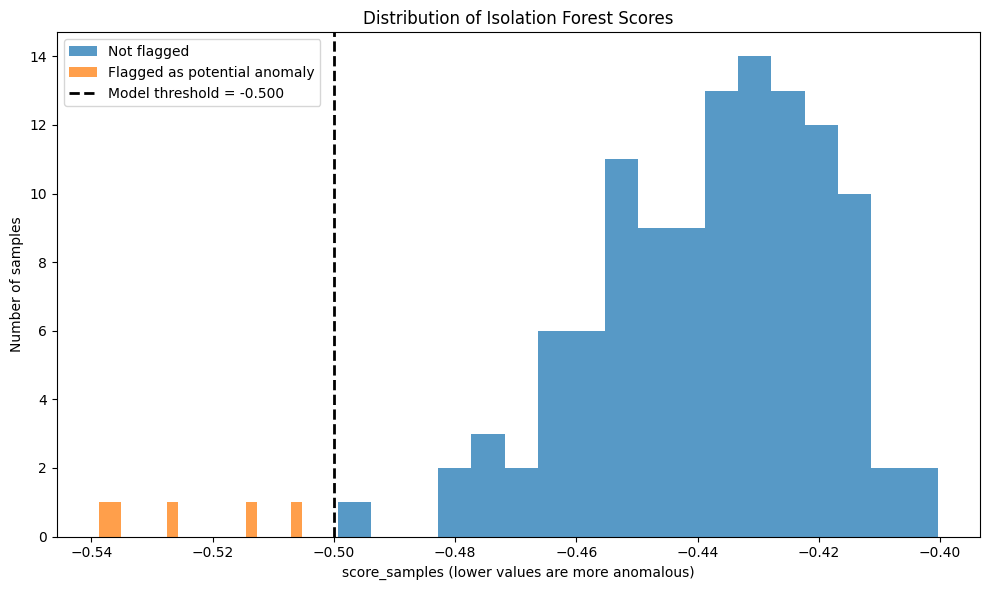

In [19]:
# Retrieve the raw score threshold used by the fitted Isolation Forest.
score_threshold = gene_model.offset_

# Plot score distributions for samples flagged and not flagged by the model.
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(
    gene_sample_scores[gene_predictions == 1],
    bins=18, alpha=0.75, label="Not flagged",
)
ax.hist(
    gene_sample_scores[gene_predictions == -1],
    bins=18, alpha=0.75, label="Flagged as potential anomaly",
)
ax.axvline(
    score_threshold,
    color="black", linestyle="--", linewidth=2,
    label=f"Model threshold = {score_threshold:.3f}",
)
ax.set_xlabel("score_samples (lower values are more anomalous)")
ax.set_ylabel("Number of samples")
ax.set_title("Distribution of Isolation Forest Scores")
ax.legend()
fig.tight_layout()
plt.show()

### 15.2. Heatmap Ordered by Anomaly Score

This heatmap displays standardized gene-expression values for all samples. Samples are ordered from lowest to highest raw Isolation Forest score, so the most anomalous-scoring samples appear at the top. A star in a sample label indicates that Isolation Forest flagged that sample.

The data are synthetic and are used here to demonstrate visualization only.

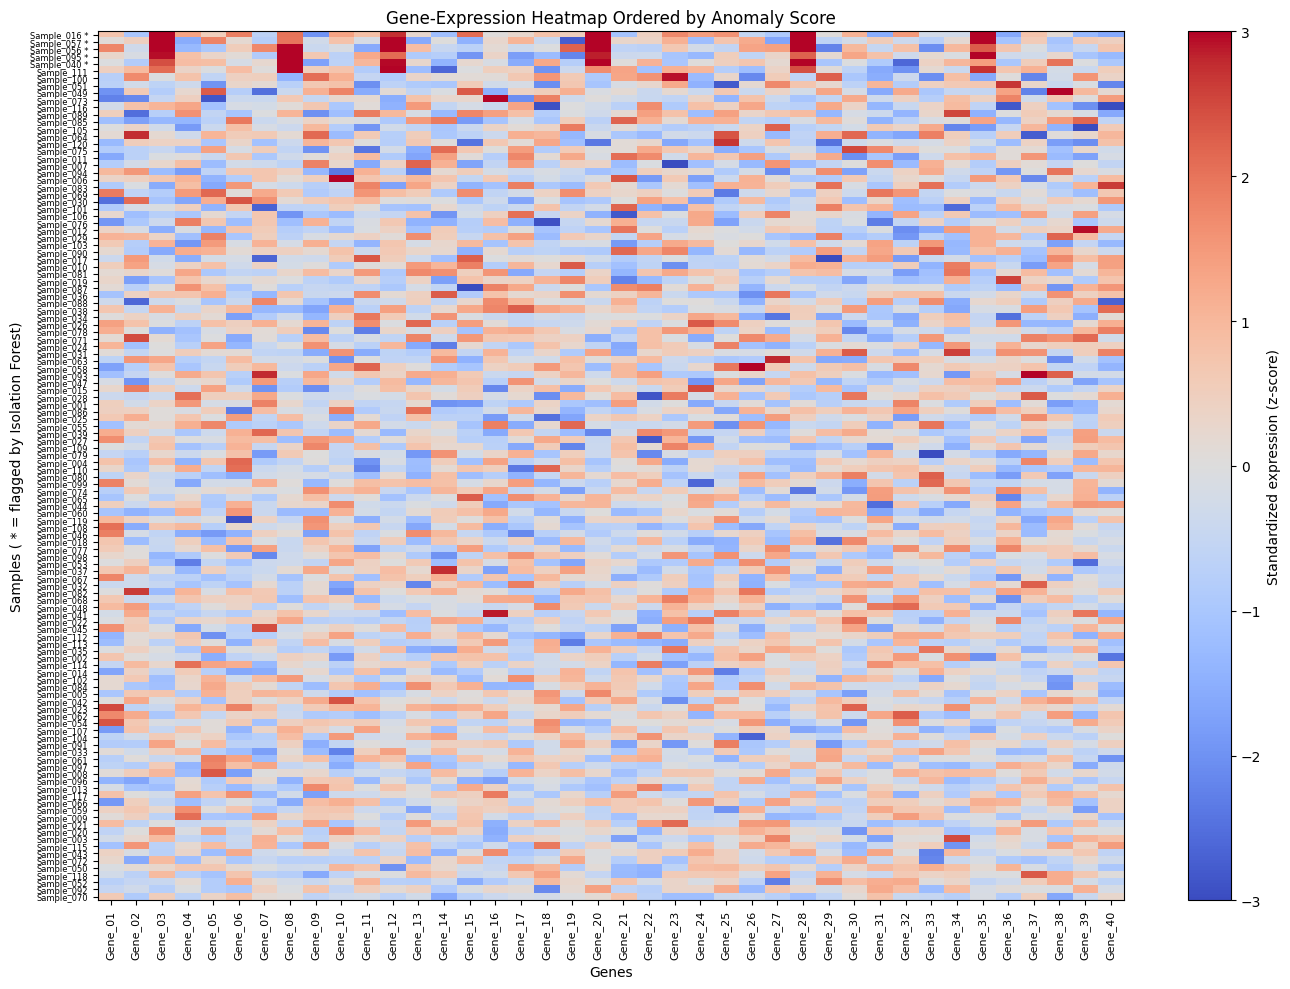

In [20]:
# Order samples from the lowest (most anomalous) raw score to the highest.
score_order = np.argsort(gene_sample_scores)
ordered_scaled = X_expression_scaled[score_order, :]
ordered_predictions = gene_predictions[score_order]
ordered_sample_ids = expression_df.index.to_numpy()[score_order]

# Add an asterisk to labels for samples flagged by the model.
ordered_labels = [
    f"{sample_id} *" if prediction == -1 else sample_id
    for sample_id, prediction in zip(ordered_sample_ids, ordered_predictions)
]

# Display standardized expression values with a diverging color map.
fig, ax = plt.subplots(figsize=(14, 10))
heatmap = ax.imshow(
    ordered_scaled,
    aspect="auto",
    interpolation="nearest",
    cmap="coolwarm",
    vmin=-3,
    vmax=3,
)
fig.colorbar(heatmap, ax=ax, label="Standardized expression (z-score)")
ax.set_xticks(np.arange(n_genes))
ax.set_xticklabels(gene_names, rotation=90, fontsize=8)
ax.set_yticks(np.arange(n_samples))
ax.set_yticklabels(ordered_labels, fontsize=6)
ax.set_xlabel("Genes")
ax.set_ylabel("Samples ( * = flagged by Isolation Forest)")
ax.set_title("Gene-Expression Heatmap Ordered by Anomaly Score")
fig.tight_layout()
plt.show()

## 16. Evaluate the Synthetic Gene Expression Example

The model did not use `biological_truth` during fitting. We now compare its predictions with the labels created when we injected synthetic shifts.

Because the model uses `contamination="auto"`, the number of flagged samples does not have to equal the number of artificially modified samples.

In [21]:
# Convert predictions to binary form: 1 = predicted anomaly, 0 = not flagged.
gene_pred_binary = (gene_predictions == -1).astype(int)

# Calculate evaluation metrics against the synthetic ground truth.
gene_precision = precision_score(
    biological_truth,
    gene_pred_binary,
    zero_division=0,
)
gene_recall = recall_score(
    biological_truth,
    gene_pred_binary,
    zero_division=0,
)
gene_f1 = f1_score(
    biological_truth,
    gene_pred_binary,
    zero_division=0,
)

print(f"Precision: {gene_precision:.3f}")
print(f"Recall:    {gene_recall:.3f}")
print(f"F1-score:  {gene_f1:.3f}")

print("Confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(biological_truth, gene_pred_binary))

print(classification_report(
    biological_truth,
    gene_pred_binary,
    target_names=["Ordinary", "Artificial anomaly"],
    zero_division=0,
))

Precision: 1.000
Recall:    0.833
F1-score:  0.909
Confusion matrix (rows=true, columns=predicted):
[[114   0]
 [  1   5]]
                    precision    recall  f1-score   support

          Ordinary       0.99      1.00      1.00       114
Artificial anomaly       1.00      0.83      0.91         6

          accuracy                           0.99       120
         macro avg       1.00      0.92      0.95       120
      weighted avg       0.99      0.99      0.99       120



### 16.1. Confusion Matrix for the Gene-Expression Example

Because this tutorial deliberately injected anomalies into a synthetic dataset, the hidden simulation labels can be used for evaluation. In a real unlabeled dataset, the true confusion matrix and standard classification metrics are not available unless trusted reference labels exist.

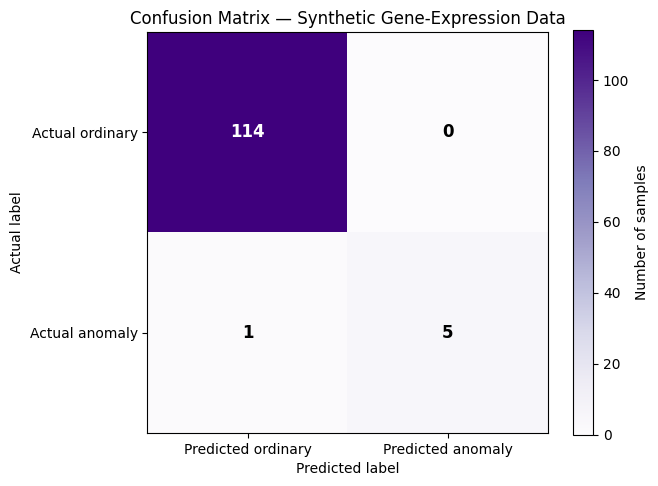

In [22]:
# Compare the simulated ground truth with the Isolation Forest predictions.
gene_cm = confusion_matrix(
    biological_truth,
    gene_pred_binary,
    labels=[0, 1],
)

fig, ax = plt.subplots(figsize=(6.5, 5))
image = ax.imshow(gene_cm, cmap="Purples")
fig.colorbar(image, ax=ax, label="Number of samples")
ax.set_xticks([0, 1], labels=["Predicted ordinary", "Predicted anomaly"])
ax.set_yticks([0, 1], labels=["Actual ordinary", "Actual anomaly"])
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_title("Confusion Matrix — Synthetic Gene-Expression Data")

threshold = gene_cm.max() / 2 if gene_cm.size else 0
for row in range(gene_cm.shape[0]):
    for col in range(gene_cm.shape[1]):
        ax.text(
            col, row, f"{gene_cm[row, col]:,}",
            ha="center", va="center",
            color="white" if gene_cm[row, col] > threshold else "black",
            fontsize=12, fontweight="bold",
        )

fig.tight_layout()
plt.show()

## 17. Visualize the Samples Using PCA

Gene-expression datasets can contain many features. **Principal Component Analysis (PCA)** projects the data into a lower-dimensional representation that is easier to visualize.

In this notebook, PCA is used only for visualization. It is **not** the anomaly detector; the anomaly predictions come from Isolation Forest.

A sample that appears close to other samples in a two-dimensional PCA plot may still be unusual in the original high-dimensional space. PCA cannot preserve all information in two dimensions.

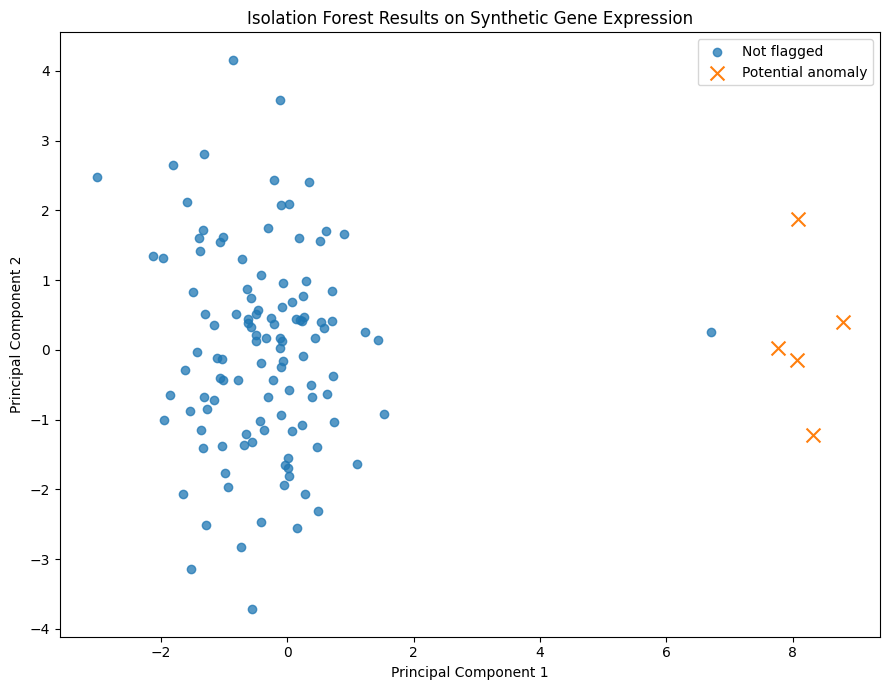

Explained variance ratio: [0.1  0.05]
Total variance represented in 2D: 0.15


In [23]:
# Project the standardized profiles into two principal components.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_expression_scaled)

# Identify samples flagged by Isolation Forest.
pca_anomaly_mask = gene_predictions == -1

# Plot samples not flagged as anomalies.
plt.figure(figsize=(9, 7))
plt.scatter(
    X_pca[~pca_anomaly_mask, 0],
    X_pca[~pca_anomaly_mask, 1],
    label="Not flagged",
    alpha=0.75,
)

# Plot samples flagged as potential anomalies.
plt.scatter(
    X_pca[pca_anomaly_mask, 0],
    X_pca[pca_anomaly_mask, 1],
    label="Potential anomaly",
    marker="x",
    s=100,
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Isolation Forest Results on Synthetic Gene Expression")
plt.legend()
plt.tight_layout()
plt.show()

print(
    "Explained variance ratio:",
    np.round(pca.explained_variance_ratio_, 3),
)
print(
    "Total variance represented in 2D:",
    round(float(pca.explained_variance_ratio_.sum()), 3),
)

## 18. Which Genes Differ Most in a Flagged Sample?

Isolation Forest does not directly provide a simple causal explanation such as “this gene caused the anomaly.” As an exploratory step, we can compare a flagged sample with the dataset-wide mean for each gene.

For each gene, we calculate the absolute standardized deviation:

$$
d_j = \left|\frac{x_j-\mu_j}{\sigma_j}\right|
$$

where:

- $x_j$ is the selected sample's value for gene $j$.
- $\mu_j$ is the dataset-wide mean for gene $j$.
- $\sigma_j$ is the dataset-wide standard deviation for gene $j$.
- $d_j$ is the absolute standardized deviation for gene $j$.

This ranking identifies genes with unusually different values in the selected sample. It does **not** establish causation, disease association, or statistical significance.

In [24]:
# Select the sample with the lowest raw Isolation Forest score.
most_anomalous_sample_id = gene_results["score_samples"].idxmin()

# Retrieve its expression profile.
selected_profile = expression_df.loc[most_anomalous_sample_id]

# Calculate the mean and standard deviation of each gene.
gene_means = expression_df.mean(axis=0)
gene_stds = expression_df.std(axis=0, ddof=0).replace(0, np.nan)

# Calculate the absolute standardized deviation for each gene.
absolute_standardized_deviation = (
    (selected_profile - gene_means) / gene_stds
).abs()

# Create a ranked table for exploratory review.
gene_deviation_table = pd.DataFrame({
    "sample_value": selected_profile,
    "dataset_mean": gene_means,
    "absolute_standardized_deviation": absolute_standardized_deviation,
}).sort_values(
    "absolute_standardized_deviation",
    ascending=False,
)

print("Selected sample:", most_anomalous_sample_id)
display(gene_deviation_table.head(10))

Selected sample: Sample_016


,sample_value,dataset_mean,absolute_standardized_deviation
Gene_03,10.333964,5.124059,3.566582
Gene_20,10.340805,5.247691,3.531813
Gene_28,9.638204,5.253097,3.222271
Gene_35,9.454748,5.134414,3.128413
Gene_12,9.691346,5.292137,2.726792
Gene_15,7.445752,5.244044,2.108536
Gene_08,8.658872,5.354188,2.008818
Gene_09,3.221280,5.058543,1.945593
Gene_06,6.876796,4.911291,1.855029
Gene_23,6.882024,5.045029,1.723337


### 18.1. Visualize the Top 10 Gene Deviations

A horizontal bar chart makes the largest absolute standardized deviations easier to compare. Bar length represents deviation magnitude, while bar direction and color show whether the selected sample's expression is above or below the dataset-wide mean.

These deviations are exploratory clues, not evidence of causality or statistical significance.

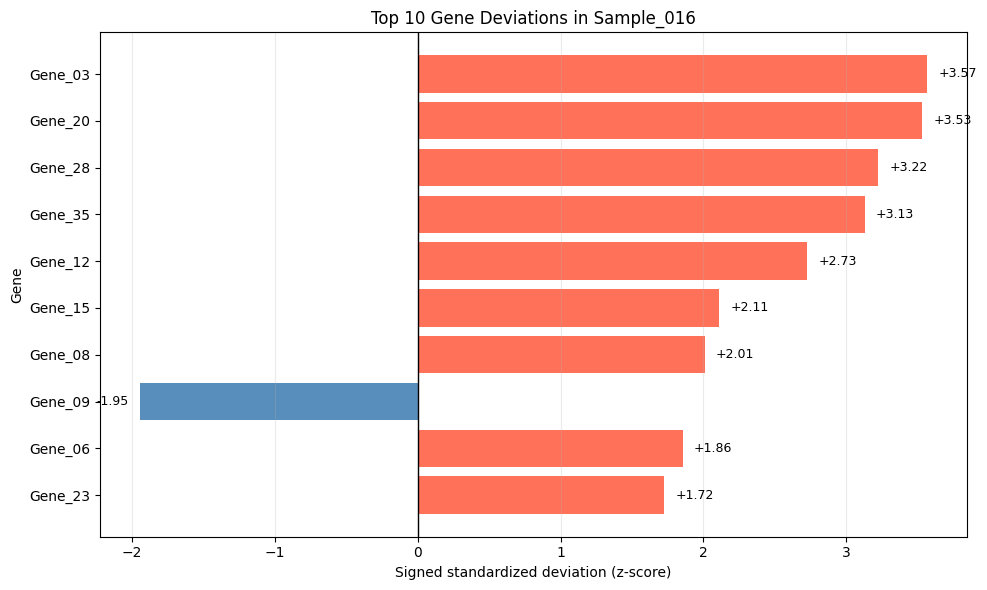

In [25]:
# Select the ten genes with the largest absolute standardized deviations.
top_gene_table = gene_deviation_table.head(10).copy()

# Calculate signed z-scores to show the direction of each deviation.
signed_z_scores = (
    (top_gene_table["sample_value"] - top_gene_table["dataset_mean"])
    / gene_stds.loc[top_gene_table.index]
)

# Use different colors for values above and below the dataset-wide mean.
bar_colors = [
    "tomato" if value > 0 else "steelblue"
    for value in signed_z_scores
]

fig, ax = plt.subplots(figsize=(10, 6))
y_positions = np.arange(len(top_gene_table))
ax.barh(
    y_positions,
    signed_z_scores.to_numpy(),
    color=bar_colors,
    alpha=0.9,
)
ax.set_yticks(y_positions, labels=top_gene_table.index)
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Signed standardized deviation (z-score)")
ax.set_ylabel("Gene")
ax.set_title(f"Top 10 Gene Deviations in {most_anomalous_sample_id}")
ax.grid(axis="x", alpha=0.25)

# Label bars with their signed z-score values.
for position, value in enumerate(signed_z_scores.to_numpy()):
    horizontal_alignment = "left" if value >= 0 else "right"
    offset = 0.08 if value >= 0 else -0.08
    ax.text(
        value + offset, position, f"{value:+.2f}",
        va="center", ha=horizontal_alignment, fontsize=9,
    )

fig.tight_layout()
plt.show()

## 19. Practical Checklist for Real Bioinformatics Data

Before applying the workflow to a real dataset, consider the following:

- Confirm what each row and column represents.
- Check sample identifiers, duplicate records, missing values, and infinite values.
- Understand the assay and expression units.
- Review normalization and transformation choices.
- Investigate possible batch effects and differences in cell composition.
- Check whether the selected genes are informative for the question.
- Test the sensitivity of results to `contamination` and `random_state`.
- Review flagged samples using independent evidence and domain expertise.
- Record package versions, preprocessing steps, parameters, and random seeds.
- Respect data-use licenses, privacy requirements, and institutional rules.

Do not replace missing expression values with zero without a scientifically justified reason. A flagged sample is a candidate for further review, not a final conclusion.

## 20. Common Mistakes

1. **Treating `-1` as a diagnosis.** It only means the model flagged the observation as an outlier.
2. **Treating `contamination` as ground truth.** It helps set the decision threshold; it does not establish the true anomaly rate.
3. **Misreading score direction.** In scikit-learn, lower `score_samples` values generally indicate more anomalous observations.
4. **Assuming every outlier is an error.** An unusual profile may be biologically meaningful or may reflect a technical issue.
5. **Ignoring preprocessing.** Batch effects, low-information genes, noise, and transformations can change the result.
6. **Over-interpreting a PCA plot.** A two-dimensional projection does not show every distinction in the original feature space.
7. **Using synthetic performance as proof of real-world performance.** Artificial anomalies are usually simpler than real biological variation.

## 21. Isolation Forest vs. LOF vs. One-Class SVM

| Method | Main idea | Practical note |
|---|---|---|
| Isolation Forest | Randomly isolate observations | A useful starting point for many high-dimensional datasets |
| Local Outlier Factor (LOF) | Compare local sample density | Can help when local density differences matter |
| One-Class SVM | Learn a boundary around typical observations | Scaling and parameter selection can be important |

No method is best for every dataset. Compare methods using appropriate validation and scientific review.

## 22. Quick Reference

```python
from sklearn.ensemble import IsolationForest

# Initialize the model.
model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42,
    n_jobs=-1,
)

# Fit without anomaly labels.
model.fit(X)

# Predict: 1 = inlier, -1 = outlier.
labels = model.predict(X)

# Lower values generally indicate more anomalous observations.
raw_scores = model.score_samples(X)

# Negative values generally indicate observations flagged as outliers.
decision_scores = model.decision_function(X)
```

### Output summary

- `predict`: `1` means inlier; `-1` means outlier.
- `score_samples`: lower values generally indicate more anomalous samples.
- `decision_function`: values below zero are generally classified as outliers.

## 23. Exercises

1. Change `n_estimators` to 50, 100, 200, and 500. Compare the stability of sample rankings.
2. Try `contamination` values of 0.01, 0.05, and 0.10. Compare the number of flagged samples.
3. Find the ten samples with the lowest `score_samples()` and inspect their features.
4. Increase the number of genes from 40 to 100. Discuss how dimensionality may affect anomaly detection.
5. Interpret the PCA plot. Do all flagged samples appear far away from the others in two dimensions?
6. Investigate the genes with the largest standardized deviations in one flagged sample. Explain why this does not prove a biological cause.
7. Replace the synthetic matrix with a real, appropriately preprocessed expression dataset. Document the data source, preprocessing, and limitations.

## 24. Further Reading

- [scikit-learn: IsolationForest API documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html)
- [scikit-learn: Novelty and Outlier Detection](https://scikit-learn.org/stable/modules/outlier_detection.html)
- Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). *Isolation Forest*. IEEE International Conference on Data Mining. [DOI: 10.1109/ICDM.2008.17](https://doi.org/10.1109/ICDM.2008.17)
- [scikit-learn: PCA documentation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)

## Conclusion

Isolation Forest identifies observations that can often be isolated with relatively few randomized splits. In this notebook, we explored its intuition, trained it on synthetic two-dimensional data, evaluated it using artificial labels, and applied it to a synthetic gene-expression matrix.

The central lesson for bioinformatics is that **statistical anomaly is not the same as biological abnormality or a clinical diagnosis**. Model output should be treated as a starting point for careful investigation, not as a final conclusion.